# Employee Performance Category Prediction

**Goal:** predict `Performance_Category` (High / Average / Low Performer) for the employees in `perf_test.csv`.
**Metric:** accuracy.

**How the three files are used**
| File | Role |
|---|---|
| `perf_train.csv` | The **only** data used to build, tune and validate the model |
| `perf_test.csv` | **Unseen** data. It has no labels, so we only predict it at the very end |

Because the test set has no answers, we measure model quality **inside the training data** (cross-validation and a hold-out split). The real test accuracy is calculated by the hackathon platform after you submit.

**Workflow in this notebook**
1. Load the data
2. Explore it (target, missing values, which features matter)
3. Prepare features
4. Compare models with cross-validation
5. Check the best model on a hold-out set
6. Tune it
7. See which features drive predictions
8. Train the final model and write `submission.csv`

> Put `perf_train.csv`, `perf_test.csv` and `sample_submission.csv` in the **same folder** as this notebook, then run the cells from top to bottom.

## Step 1: Imports and settings

In [1]:
import warnings
warnings.filterwarnings("ignore")

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)

## Step 2: Load the data
We have a labelled training set (2000 rows), an unlabelled and unseen test set (500 rows) and a sample submission that shows the required output format. From here until Step 9 we work **only with the training data**.

In [2]:
train = pd.read_csv("perf_train.csv")
test = pd.read_csv("perf_test.csv")
sample = pd.read_csv("sample_submission.csv")

print("train:", train.shape, "| test:", test.shape, "| sample submission:", sample.shape)
train.head()

train: (2000, 22) | test: (500, 21) | sample submission: (500, 2)


,Employee_ID,Age,Gender,City,Education_Level,Department,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,Certifications,Work_Life_Balance,Job_Satisfaction,Manager_Rating,Overtime_Hours,Commute_Time_Min,Laptop_Issue_Count,Cafeteria_Rating,Internet_Stability,Last_Promotion_Years,Absenteeism_Days,Performance_Category
0,10001,49.0,Male,Bengaluru,Post Graduate,Sales,NaN,NaN,15.0,20.0,1.0,2.0,3.0,3.2,43.0,11.0,3.0,1.0,Good,2.1,1.0,Average Performer
1,10002,35.0,Female,Bengaluru,Post Graduate,Analytics,0.8,129555.0,15.0,163.0,0.0,5.0,4.0,2.3,43.0,128.0,6.0,5.0,Average,0.8,18.0,Low Performer
2,10003,28.0,Female,NaN,Graduate,Finance,12.7,55760.0,NaN,213.0,1.0,3.0,1.0,4.2,50.0,34.0,1.0,4.0,Poor,1.3,12.0,Average Performer
3,10004,41.0,Male,Hyderabad,Graduate,Sales,4.9,128174.0,NaN,209.0,5.0,1.0,2.0,4.5,78.0,168.0,7.0,5.0,Good,4.2,11.0,Average Performer
4,10005,39.0,Male,NaN,Graduate,Sales,1.2,145192.0,5.0,117.0,0.0,NaN,3.0,4.2,20.0,117.0,9.0,2.0,Excellent,2.5,24.0,Low Performer


## Step 3: Explore the data (EDA)
Before modelling, check three things: the **target distribution**, **missing values** and **which features relate to the target**.

### 3.1 Target distribution
If one class dominates, a model that always predicts it already gets a decent accuracy. That number is our baseline to beat.

Performance_Category
Average Performer    1129
Low Performer         663
High Performer        208
Name: count, dtype: int64

Performance_Category
Average Performer    0.564
Low Performer        0.332
High Performer       0.104
Name: count, dtype: float64

Majority-class baseline accuracy: 0.5645


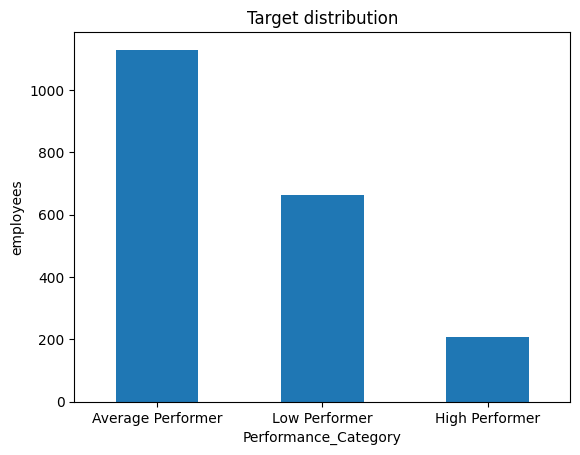

In [3]:
target = "Performance_Category"
counts = train[target].value_counts()
print(counts)
print()
print((counts / len(train)).round(3))
print("\nMajority-class baseline accuracy:", round(counts.max() / len(train), 4))

counts.plot(kind="bar", title="Target distribution", rot=0)
plt.ylabel("employees")
plt.show()

### 3.2 Missing values
This dataset has blanks in almost every column, so how we handle them matters.

In [4]:
missing = pd.DataFrame({
    "train_missing_%": (train.isna().mean() * 100).round(1),
    "test_missing_%": (test.isna().mean() * 100).round(1),
}).drop(index=target)
missing.sort_values("train_missing_%", ascending=False)

,train_missing_%,test_missing_%
Internet_Stability,17.2,19.2
Absenteeism_Days,16.0,16.0
Certifications,15.2,16.4
Training_Hours,14.9,13.6
Projects_Completed,14.4,16.4
Cafeteria_Rating,14.2,15.0
Experience_Years,12.6,14.0
City,10.5,9.2
Department,10.0,9.8
Commute_Time_Min,9.8,11.4


### 3.3 Which features relate to performance?
Correlation with the target (classes encoded as Low=0, Average=1, High=2) gives a quick first ranking for numeric features.

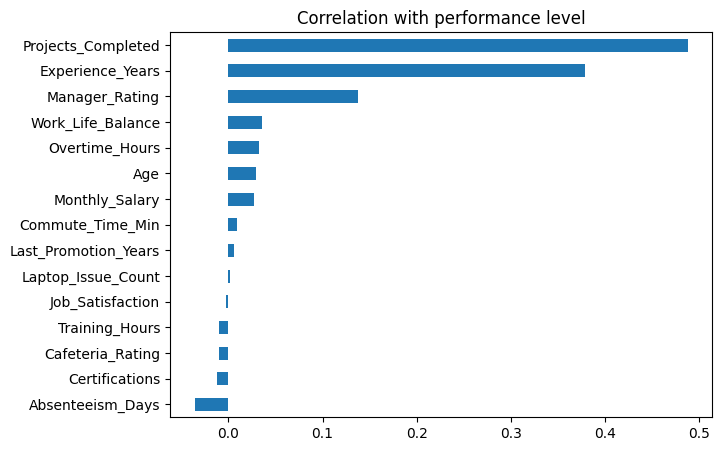

In [5]:
order = {"Low Performer": 0, "Average Performer": 1, "High Performer": 2}
y_num = train[target].map(order)

num_cols = train.select_dtypes("number").columns.drop("Employee_ID")
corr = train[num_cols].corrwith(y_num).sort_values()
corr.plot(kind="barh", figsize=(7, 5), title="Correlation with performance level")
plt.show()

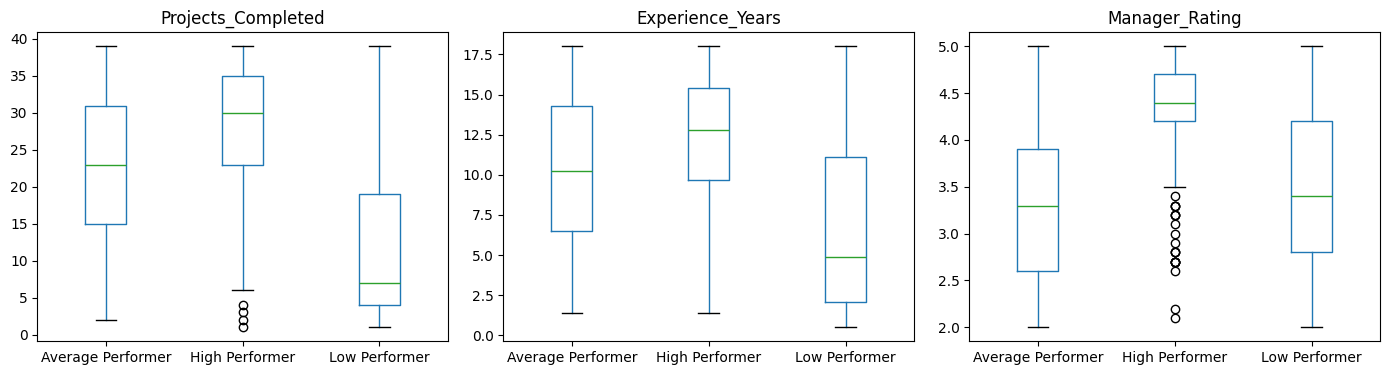

In [6]:
# Look at the two strongest features by class
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Projects_Completed", "Experience_Years", "Manager_Rating"]):
    train.boxplot(column=col, by=target, ax=ax, grid=False)
    ax.set_title(col); ax.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

**What we learn:** Projects_Completed and Experience_Years separate the classes the most, Manager_Rating helps a little, and many columns (cafeteria rating, laptop issues, commute) look like noise. Tree-based models handle this well because they can ignore useless columns.

## Step 4: Prepare the features
- Drop `Employee_ID` (just an identifier, not a feature) and the target.
- Add three simple engineered features:
  - `n_missing`: how many fields are blank for the employee
  - `proj_per_exp`: projects per year of experience
  - `sal_per_exp`: salary per year of experience
- Fill blank **numeric** values with the **median** and blank **categorical** values with the **mode** (most frequent value).
- The fill values are learned from the **training data only** and then applied to both train and test.
- `n_missing` is counted **before** filling, so the model still knows which rows had blanks.

One important rule: **everything is learned from the training data only**. The category list comes from train. If the unseen test data ever contains a category the model has not seen, it is replaced by the training mode, exactly as it would be in real life.

In [7]:
cat_cols = ["Gender", "City", "Education_Level", "Department", "Internet_Stability"]

num_feats = [c for c in train.columns if c not in cat_cols + ["Employee_ID", target]]

# Fill values learned from TRAIN only
medians = train[num_feats].median()
modes = {c: train[c].mode()[0] for c in cat_cols}
levels = {c: sorted(train[c].dropna().unique()) for c in cat_cols}

print("Median examples:", medians.head(3).round(1).to_dict())
print("Mode examples:", {k: modes[k] for k in list(modes)[:3]})

def prepare(df):
    X = df.drop(columns=["Employee_ID", target], errors="ignore").copy()
    X["n_missing"] = X.isna().sum(axis=1)            # count blanks BEFORE filling
    X[num_feats] = X[num_feats].fillna(medians)       # numeric -> median
    X["proj_per_exp"] = X["Projects_Completed"] / (X["Experience_Years"] + 0.5)
    X["sal_per_exp"] = X["Monthly_Salary"] / (X["Experience_Years"] + 0.5)
    for c in cat_cols:
        s = X[c].where(X[c].isin(levels[c]), modes[c])   # blanks and unseen values -> mode
        X[c] = pd.Categorical(s, categories=levels[c])
    return X

X = prepare(train)
X_test = prepare(test)
y = train[target]

# One-hot version for models that cannot read categories directly
X_ohe = pd.get_dummies(X, columns=cat_cols, dtype=float)

print("features:", X.shape[1])
print("Missing values left -> train:", int(X.isna().sum().sum()), "| test:", int(X_test.isna().sum().sum()))
X.head()

Median examples: {'Age': 40.0, 'Experience_Years': 9.3, 'Monthly_Salary': 81830.0}
Mode examples: {'Gender': 'Male', 'City': 'Delhi', 'Education_Level': 'Graduate'}
features: 23
Missing values left -> train: 0 | test: 0


,Age,Gender,City,Education_Level,Department,Experience_Years,Monthly_Salary,Projects_Completed,Training_Hours,Certifications,Work_Life_Balance,Job_Satisfaction,Manager_Rating,Overtime_Hours,Commute_Time_Min,Laptop_Issue_Count,Cafeteria_Rating,Internet_Stability,Last_Promotion_Years,Absenteeism_Days,n_missing,proj_per_exp,sal_per_exp
0,49.0,Male,Bengaluru,Post Graduate,Sales,9.3,81830.0,15.0,20.0,1.0,2.0,3.0,3.2,43.0,11.0,3.0,1.0,Good,2.1,1.0,2,1.530612,8350.000000
1,35.0,Female,Bengaluru,Post Graduate,Analytics,0.8,129555.0,15.0,163.0,0.0,5.0,4.0,2.3,43.0,128.0,6.0,5.0,Average,0.8,18.0,0,11.538462,99657.692308
2,28.0,Female,Delhi,Graduate,Finance,12.7,55760.0,20.0,213.0,1.0,3.0,1.0,4.2,50.0,34.0,1.0,4.0,Poor,1.3,12.0,2,1.515152,4224.242424
3,41.0,Male,Hyderabad,Graduate,Sales,4.9,128174.0,20.0,209.0,5.0,1.0,2.0,4.5,78.0,168.0,7.0,5.0,Good,4.2,11.0,1,3.703704,23735.925926
4,39.0,Male,Delhi,Graduate,Sales,1.2,145192.0,5.0,117.0,0.0,3.0,3.0,4.2,20.0,117.0,9.0,2.0,Excellent,2.5,24.0,2,2.941176,85407.058824


## Step 5: Compare models with cross-validation
Stratified 5-fold cross-validation trains each model 5 times on different 80% slices and tests on the remaining 20%. The average is a much more reliable estimate than a single split, especially with only 2000 rows.

Logistic Regression       0.7845  (+/- 0.0220)
Random Forest             0.8685  (+/- 0.0145)
Hist Gradient Boosting    0.8810  (+/- 0.0196)


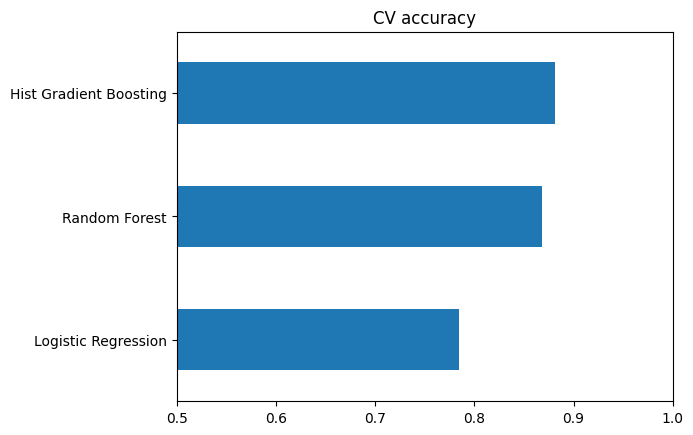

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "Logistic Regression": (
        make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000)),
        X_ohe,
    ),
    "Random Forest": (
        make_pipeline(SimpleImputer(strategy="median"),
                      RandomForestClassifier(n_estimators=500, min_samples_leaf=3, n_jobs=-1, random_state=0)),
        X_ohe,
    ),
    "Hist Gradient Boosting": (
        HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_depth=4,
                                       l2_regularization=1.0, categorical_features="from_dtype", random_state=0),
        X,
    ),
}

results = {}
for name, (model, data) in candidates.items():
    scores = cross_val_score(model, data, y, cv=cv, scoring="accuracy")
    results[name] = scores.mean()
    print(f"{name:25s} {scores.mean():.4f}  (+/- {scores.std():.4f})")

pd.Series(results).sort_values().plot(kind="barh", title="CV accuracy", xlim=(0.5, 1))
plt.show()

Gradient boosting wins clearly, so we carry it forward.

## Step 6: Hold-out check and error analysis
Cross-validation gives the score; a confusion matrix shows **where** the model makes mistakes. We keep 20% of the training data aside, fit on the other 80%, and inspect the predictions.

Hold-out accuracy: 0.885

                   precision    recall  f1-score   support

Average Performer       0.87      0.97      0.92       226
   High Performer       0.81      0.63      0.71        41
    Low Performer       0.93      0.82      0.87       133

         accuracy                           0.89       400
        macro avg       0.87      0.81      0.83       400
     weighted avg       0.89      0.89      0.88       400



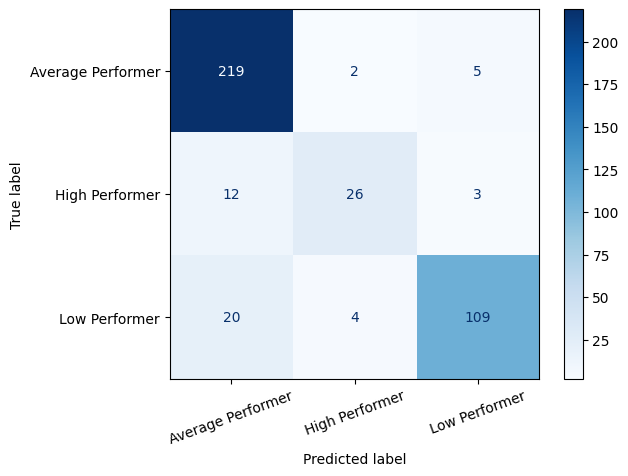

In [9]:
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

model = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_depth=4,
                                       l2_regularization=1.0, categorical_features="from_dtype", random_state=0)
model.fit(X_tr, y_tr)
pred = model.predict(X_val)

print("Hold-out accuracy:", round(accuracy_score(y_val, pred), 4))
print()
print(classification_report(y_val, pred))

ConfusionMatrixDisplay.from_predictions(y_val, pred, xticks_rotation=20, cmap="Blues")
plt.show()

Read the report: **recall** for *High Performer* is usually the weakest because it is the smallest class (about 10%). Improving that class is the best way to raise overall accuracy further.

## Step 7: Tune the model
Instead of trying every combination (slow), a **randomized search** tests a handful of randomly chosen combinations. With `n_jobs=-1` it also uses all CPU cores in parallel, so it finishes in well under a minute and finds settings almost as good as a full grid.

> Want a more thorough search? Increase `n_iter` (for example to 20). It is slower, but the score usually changes by less than 0.5%.

In [10]:
from sklearn.model_selection import RandomizedSearchCV

param_space = {
    "learning_rate": [0.03, 0.05, 0.08],
    "max_depth": [3, 4, 6],
    "max_iter": [100, 200, 300],
    "min_samples_leaf": [10, 30],
}

search = RandomizedSearchCV(
    HistGradientBoostingClassifier(l2_regularization=1.0, categorical_features="from_dtype", random_state=0),
    param_distributions=param_space,
    n_iter=8,                 # number of combinations to try
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,                # use all CPU cores
    random_state=RANDOM_STATE,
).fit(X, y)

best_score, best_params = search.best_score_, search.best_params_
print("Best CV accuracy:", round(best_score, 4))
print("Best params:", best_params)

Best CV accuracy: 0.887
Best params: {'min_samples_leaf': 30, 'max_iter': 100, 'max_depth': 6, 'learning_rate': 0.08}


## Step 8: What drives the predictions? (feature importance)
Permutation importance shuffles one feature at a time on the hold-out set and measures how much accuracy drops. A big drop means the model relies on that feature.

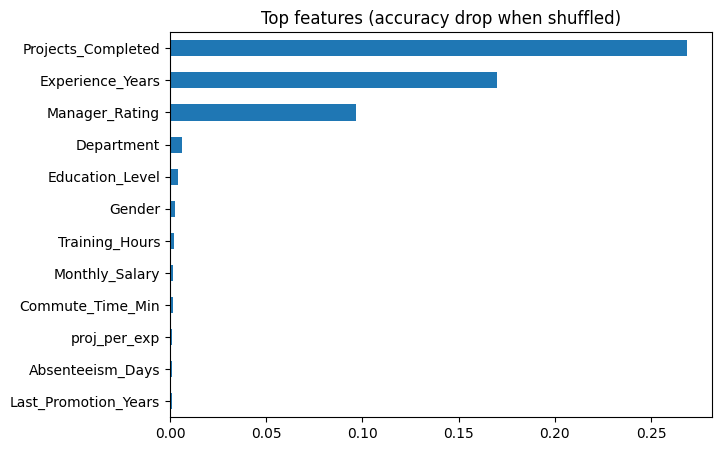

In [11]:
best_model = HistGradientBoostingClassifier(**best_params, l2_regularization=1.0,
                                            categorical_features="from_dtype", random_state=0).fit(X_tr, y_tr)

imp = permutation_importance(best_model, X_val, y_val, n_repeats=10, random_state=0, scoring="accuracy")
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values()

importance.tail(12).plot(kind="barh", figsize=(7, 5), title="Top features (accuracy drop when shuffled)")
plt.show()

This is also your **business insight** for the hackathon story: which factors really separate high performers from those who need support.

## Step 9: Train the final model and predict the unseen test set
The model design is now frozen. Fit it on **all** 2000 training rows, then use it, for the first time, on the unseen `perf_test.csv`. Training with 5 different random seeds and averaging their probabilities makes the predictions a bit more stable.

In [12]:
proba = 0
for seed in range(5):
    m = HistGradientBoostingClassifier(**best_params, l2_regularization=1.0,
                                       categorical_features="from_dtype", random_state=seed).fit(X, y)
    proba += m.predict_proba(X_test)

final_pred = m.classes_[proba.argmax(axis=1)]
pd.Series(final_pred).value_counts(normalize=True).round(3)

Average Performer    0.660
Low Performer        0.254
High Performer       0.086
Name: proportion, dtype: float64

## Step 10: Create the submission file
The file must contain `Employee_ID` and `Performance_Category` for every test row. We only compare it with `sample_submission.csv` to check the **format** (columns and IDs), never the predicted labels.

In [13]:
submission = pd.DataFrame({"Employee_ID": test["Employee_ID"], target: final_pred})
submission.to_csv("submission.csv", index=False)

# Format checks only (sample_submission labels are placeholders and are not compared)
assert len(submission) == len(test) == len(sample)
assert list(submission.columns) == list(sample.columns)
assert (submission["Employee_ID"].values == sample["Employee_ID"].values).all()
assert submission[target].isin(train[target].unique()).all()
print("submission.csv saved, all checks passed")
submission.head()

submission.csv saved, all checks passed


,Employee_ID,Performance_Category
0,12001,Average Performer
1,12002,Average Performer
2,12003,Low Performer
3,12004,Low Performer
4,12005,Average Performer
